<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_09_Ensemble_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 9.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

### Praktikum 9.2 Import Dataset

In [5]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

### Praktikum 9.3 Preprocessing dan Training Model

In [3]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42)
rf.fit(X_train, y_train)

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)

tree_tunggal = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

### Praktikum 9.4 Evaluasi

In [6]:
print("OOB Score Random Forest:", round(rf.oob_score_, 3))

for nama, model in [("Decision Tree Tunggal", tree_tunggal), ("Random Forest", rf),
                    ("AdaBoost", ada), ("Gradient Boosting", gb)]:
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{nama}: Akurasi Test = {acc:.3f}")

OOB Score Random Forest: 0.979
Decision Tree Tunggal: Akurasi Test = 0.944
Random Forest: Akurasi Test = 1.000
AdaBoost: Akurasi Test = 0.917
Gradient Boosting: Akurasi Test = 0.944


### Praktikum 9.5 Visualisasi

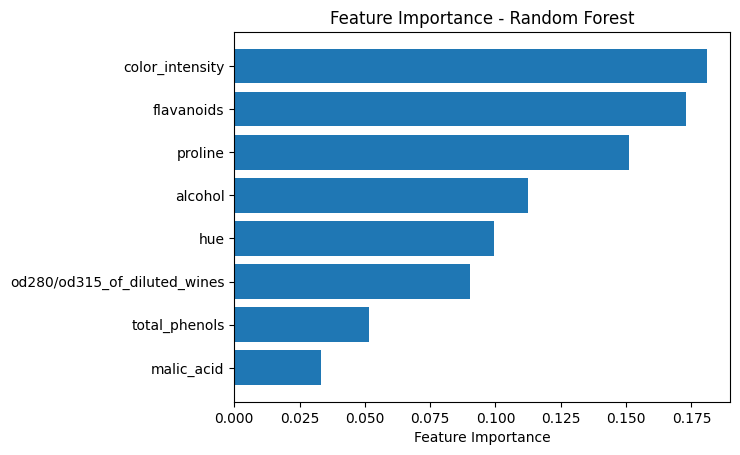

In [7]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1][:8]
plt.barh([data.feature_names[i] for i in idx][::-1], importances[idx][::-1])
plt.xlabel("Feature Importance")
plt.title("Feature Importance - Random Forest")
plt.show()

### Praktikum 1 — Pengaruh `n_estimators` (Praktikum 9.6)

In [8]:
import warnings
rows = []
for n in [10, 50, 100, 300, 500]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # n=10 dapat memunculkan peringatan "tidak semua data punya skor OOB"
        model = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=42)
        model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"n_estimators={n}: OOB={model.oob_score_:.3f}, Test Acc={acc:.3f}")
    rows.append({"n_estimators": n, "OOB": model.oob_score_, "Test Acc": acc})
hasil_n = pd.DataFrame(rows)

n_estimators=10: OOB=0.951, Test Acc=1.000
n_estimators=50: OOB=0.972, Test Acc=1.000
n_estimators=100: OOB=0.979, Test Acc=1.000
n_estimators=300: OOB=0.979, Test Acc=1.000
n_estimators=500: OOB=0.979, Test Acc=1.000


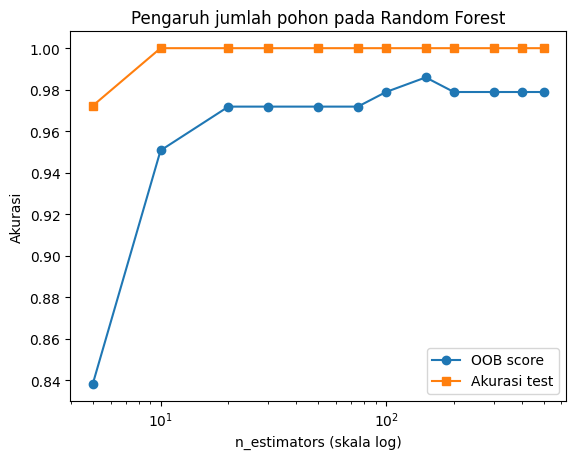

,n_estimators,OOB,Test Acc
0,10,0.951,1.0
1,50,0.972,1.0
2,100,0.979,1.0
3,300,0.979,1.0
4,500,0.979,1.0


In [9]:
# Pengaruh n_estimators lebih halus (nilai n lebih rapat) untuk melihat tren dan kestabilan
ns = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500]
oob, tes = [], []
for n in ns:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=42).fit(X_train, y_train)
    oob.append(m.oob_score_); tes.append(accuracy_score(y_test, m.predict(X_test)))
plt.plot(ns, oob, 'o-', label="OOB score")
plt.plot(ns, tes, 's-', label="Akurasi test")
plt.xscale("log"); plt.xlabel("n_estimators (skala log)"); plt.ylabel("Akurasi")
plt.title("Pengaruh jumlah pohon pada Random Forest"); plt.legend(); plt.show()
hasil_n.round(3)

### Praktikum 2 — Perbandingan Empat Model (Stratified 5-Fold CV, `f1_macro`)

Dataset: `load_wine` (seluruh data, 178 sampel, 3 kelas).

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
empat_model = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
}
skor_semua = {}
for nama, model in empat_model.items():
    skor_semua[nama] = cross_val_score(model, X, y, cv=skf, scoring="f1_macro")

tabel = pd.DataFrame({
    "F1-macro rata-rata": {n: s.mean() for n, s in skor_semua.items()},
    "Std": {n: s.std() for n, s in skor_semua.items()},
    "Min fold": {n: s.min() for n, s in skor_semua.items()},
    "Max fold": {n: s.max() for n, s in skor_semua.items()},
}).round(3).sort_values("F1-macro rata-rata", ascending=False)
tabel

,F1-macro rata-rata,Std,Min fold,Max fold
Random Forest,0.984,0.021,0.948,1.000
AdaBoost,0.929,0.044,0.864,0.972
Gradient Boosting,0.924,0.030,0.890,0.970
Decision Tree,0.896,0.036,0.836,0.946


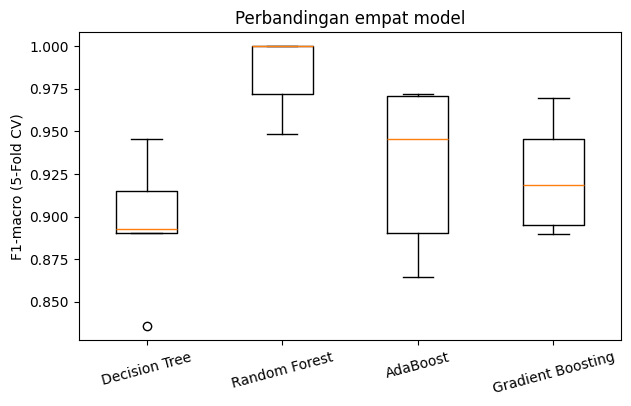

In [11]:
plt.figure(figsize=(7, 4))
plt.boxplot(list(skor_semua.values())); plt.xticks(range(1, len(skor_semua) + 1), list(skor_semua.keys()))
plt.ylabel("F1-macro (5-Fold CV)"); plt.title("Perbandingan empat model"); plt.xticks(rotation=15)
plt.show()